# A/B Test: One-Page Checkout (Saudi e-commerce app)

**Context (simulated case study).** The product team redesigned the checkout into a single page (address, delivery slot and payment on one screen).
Users who reached checkout between **5 and 18 October 2025** were randomly assigned 50/50 to the old flow (**control**) or the new flow (**treatment**).

| Item | Definition |
|---|---|
| Unit of randomisation | user (first exposure to checkout) |
| Primary metric | purchase conversion = users who paid / users who reached checkout |
| Secondary metrics | average order value (AOV), revenue per user |
| Guardrail | payment error rate (must not get worse) |
| Hypotheses | H0: p_treatment = p_control, H1: p_treatment ≠ p_control (two-sided) |
| Decision rules | alpha = 0.05, power = 80%, minimum detectable effect (MDE) = +1.5 percentage points |

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep

sns.set_theme(style="whitegrid", palette=["#1F4E79", "#F39C12", "#27AE60", "#C0392B"])
plt.rcParams["figure.dpi"] = 110
R = {}  # results collected for the report
df_raw = pd.read_csv("data/checkout_experiment.csv", parse_dates=["first_exposure_ts"])
df_raw.head()

,user_id,first_exposure_ts,group,device,user_type,city,time_on_checkout_sec,converted,order_value,payment_error
0,U006816,2025-10-05 00:00:15,control,Web,Returning,Jeddah,159,0,NaN,0
1,U047777,2025-10-05 00:00:26,treatment,iOS,Returning,Dammam,191,0,NaN,0
2,U083328,2025-10-05 00:00:56,control,Web,New,Other,129,1,622.26,0
3,U083276,2025-10-05 00:01:03,treatment,Android,New,Dammam,13,0,NaN,0
4,U029567,2025-10-05 00:01:27,control,Android,New,Dammam,67,0,NaN,0


## 1. Sample size: how many users did we need?
Planned before launch. Baseline conversion from the previous month ≈ 59%.

In [2]:
p0, mde = 0.59, 0.015
es = proportion_effectsize(p0 + mde, p0)          # Cohen's h
n_per_group = NormalIndPower().solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=1, alternative="two-sided")
R["required_n_per_group"] = int(np.ceil(n_per_group))
print(f"Cohen's h = {es:.4f}  ->  required users per group = {R['required_n_per_group']:,}")

Cohen's h = 0.0306  ->  required users per group = 16,778


## 2. Data quality before any test
Three checks: users exposed to **both** variants (contamination), bot-like sessions (< 2 seconds on checkout), and converted users without an order value.

In [3]:
grp_per_user = df_raw.groupby("user_id")["group"].nunique()
contaminated = grp_per_user[grp_per_user > 1].index
bots = df_raw["time_on_checkout_sec"] < 2
print("rows:", len(df_raw), "| users in both groups:", len(contaminated), "| bot-like rows:", int(bots.sum()))
df = df_raw[~df_raw.user_id.isin(contaminated) & ~bots].copy()
R.update(raw_rows=len(df_raw), contaminated_users=len(contaminated), bot_rows=int(bots.sum()), clean_users=len(df))
print("clean users:", len(df), "| converted without order value:", int((df.converted.eq(1) & df.order_value.isna()).sum()))

rows: 84330 | users in both groups: 330 | bot-like rows: 251


clean users: 83419 | converted without order value: 120


## 3. Sample ratio mismatch (SRM)
If randomisation worked, the split should be 50/50. A chi-square goodness-of-fit test with p < 0.001 would mean the experiment is broken and results can't be trusted.

In [4]:
counts = df.group.value_counts().reindex(["control", "treatment"])
chi2, p_srm = stats.chisquare(counts, [counts.sum() / 2] * 2)
R.update(n_control=int(counts["control"]), n_treatment=int(counts["treatment"]), srm_p=round(float(p_srm), 4))
print(counts.to_dict(), f"chi2 = {chi2:.2f}, p = {p_srm:.3f}  ->", "OK" if p_srm > 0.001 else "SRM!")

{'control': 41626, 'treatment': 41793} chi2 = 0.33, p = 0.563  -> OK


## 4. Primary metric: conversion
Two-proportion z-test and a 95% confidence interval for the difference (Newcombe).

In [5]:
g = df.groupby("group")["converted"].agg(["sum", "count", "mean"]).reindex(["control", "treatment"])
z, p_val = proportions_ztest(g["sum"].values[::-1], g["count"].values[::-1])
lo, hi = confint_proportions_2indep(g.loc["treatment", "sum"], g.loc["treatment", "count"],
                                    g.loc["control", "sum"], g.loc["control", "count"], method="newcomb")
diff = g.loc["treatment", "mean"] - g.loc["control", "mean"]
R.update(conv_control=round(g.loc["control", "mean"], 4), conv_treatment=round(g.loc["treatment", "mean"], 4),
         abs_lift=round(diff, 4), rel_lift=round(diff / g.loc["control", "mean"], 4), z=round(z, 2), p_value=float(f"{p_val:.2e}"),
         ci_low=round(lo, 4), ci_high=round(hi, 4))
print(g.round(4))
print(f"\nlift = {diff*100:+.2f} pp ({diff/g.loc['control','mean']*100:+.1f}%), z = {z:.2f}, p = {p_val:.2e}, 95% CI [{lo*100:+.2f}, {hi*100:+.2f}] pp")

             sum  count    mean
group                          
control    24070  41626  0.5782
treatment  25148  41793  0.6017

lift = +2.35 pp (+4.1%), z = 6.90, p = 5.38e-12, 95% CI [+1.68, +3.02] pp


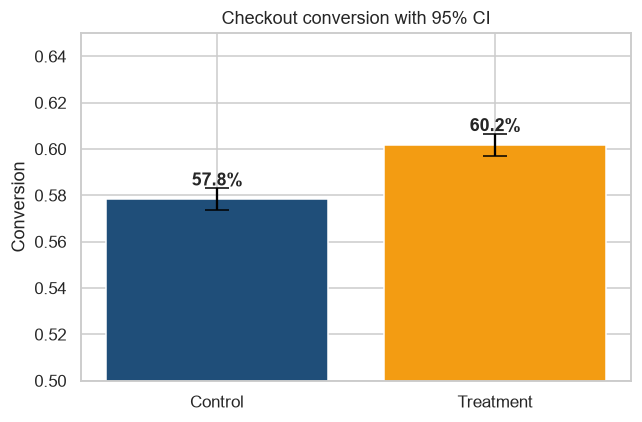

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Control", "Treatment"], g["mean"], color=["#1F4E79", "#F39C12"],
       yerr=1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"]), capsize=8)
for i, v in enumerate(g["mean"]):
    ax.text(i, v + 0.006, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_ylim(0.5, 0.65); ax.set_ylabel("Conversion"); ax.set_title("Checkout conversion with 95% CI")
plt.tight_layout(); plt.savefig("figures/01_conversion.png"); plt.show()

## 5. Effect over time: is there a novelty effect?
If the lift is large on the first days and shrinks later, part of it is curiosity, not lasting value. We judge the steady-state lift on days 4-14.

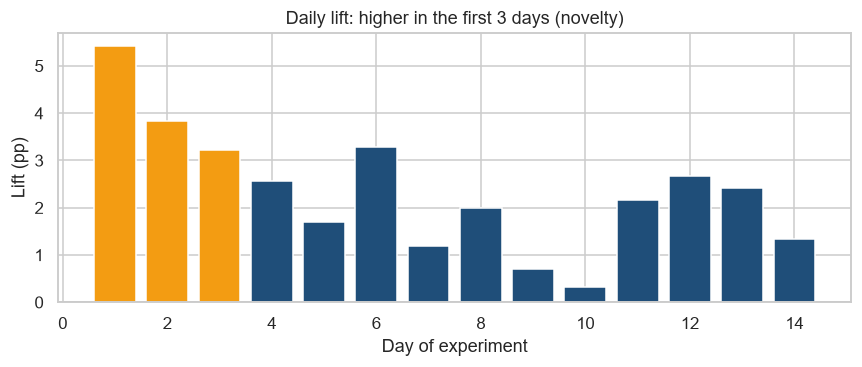

lift days 1-3: +4.18 pp | days 4-14: +1.85 pp


In [7]:
df["day"] = (df.first_exposure_ts.dt.normalize() - df.first_exposure_ts.min().normalize()).dt.days + 1
daily = df.pivot_table(index="day", columns="group", values="converted", aggfunc="mean")
daily["lift_pp"] = (daily.treatment - daily.control) * 100
early = df[df.day <= 3].groupby("group").converted.mean(); late = df[df.day > 3].groupby("group").converted.mean()
R.update(lift_days_1_3=round(early.treatment - early.control, 4), lift_days_4_14=round(late.treatment - late.control, 4))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(daily.index, daily.lift_pp, color=np.where(daily.index <= 3, "#F39C12", "#1F4E79"))
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Day of experiment"); ax.set_ylabel("Lift (pp)")
ax.set_title("Daily lift: higher in the first 3 days (novelty)")
plt.tight_layout(); plt.savefig("figures/02_novelty.png"); plt.show()
print(f"lift days 1-3: {R['lift_days_1_3']*100:+.2f} pp | days 4-14: {R['lift_days_4_14']*100:+.2f} pp")

## 6. Segments: who benefits?
Segment results are **exploratory**: testing many segments inflates false positives, so we apply a Bonferroni correction (alpha / number of tests).

In [8]:
rows = []
for d, s in df.groupby("device"):
    k = s.groupby("group").converted.agg(["sum", "count", "mean"]).reindex(["control", "treatment"])
    z_, p_ = proportions_ztest(k["sum"].values[::-1], k["count"].values[::-1])
    rows.append([d, k.loc["control", "mean"], k.loc["treatment", "mean"], (k.loc["treatment", "mean"] - k.loc["control", "mean"]) * 100, p_])
seg = pd.DataFrame(rows, columns=["device", "control", "treatment", "lift_pp", "p_value"])
seg["significant_bonferroni"] = seg.p_value < 0.05 / len(seg)
R["segments"] = seg.round(4).set_index("device").to_dict(orient="index")
seg.round(4)

,device,control,treatment,lift_pp,p_value,significant_bonferroni
0,Android,0.5559,0.5797,2.3845,0.0000,True
1,Web,0.5341,0.5215,-1.2538,0.1337,False
2,iOS,0.6139,0.6502,3.6279,0.0000,True


## 7. Secondary metrics: order value and revenue per user
Order values are right-skewed, so besides Welch's t-test we use Mann-Whitney and a bootstrap confidence interval.

AOV control 349.5 vs treatment 348.0 SAR | Welch p = 0.430 | Mann-Whitney p = 0.302
Revenue per user: 201.7 -> 208.8 SAR, diff 95% bootstrap CI [4.1, 10.1]


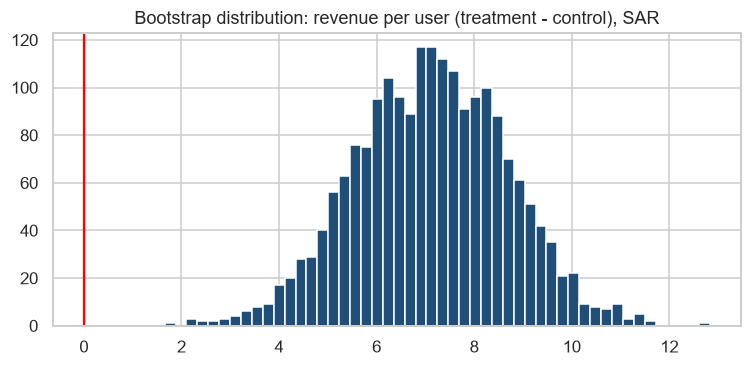

In [9]:
aov_c = df[(df.group == "control") & df.order_value.notna()].order_value
aov_t = df[(df.group == "treatment") & df.order_value.notna()].order_value
t_stat, p_t = stats.ttest_ind(aov_t, aov_c, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(aov_t, aov_c)
df["revenue"] = df.order_value.fillna(0) * df.converted
rng = np.random.default_rng(0)
rc, rt = df[df.group == "control"].revenue.values, df[df.group == "treatment"].revenue.values
boots = [rng.choice(rt, rt.size).mean() - rng.choice(rc, rc.size).mean() for _ in range(2000)]
b_lo, b_hi = np.percentile(boots, [2.5, 97.5])
R.update(aov_control=round(aov_c.mean(), 2), aov_treatment=round(aov_t.mean(), 2), aov_p_welch=round(p_t, 4), aov_p_mw=round(p_u, 4),
         rpu_control=round(rc.mean(), 2), rpu_treatment=round(rt.mean(), 2), rpu_diff=round(rt.mean() - rc.mean(), 2),
         rpu_ci=[round(b_lo, 2), round(b_hi, 2)])
print(f"AOV control {aov_c.mean():.1f} vs treatment {aov_t.mean():.1f} SAR | Welch p = {p_t:.3f} | Mann-Whitney p = {p_u:.3f}")
print(f"Revenue per user: {rc.mean():.1f} -> {rt.mean():.1f} SAR, diff 95% bootstrap CI [{b_lo:.1f}, {b_hi:.1f}]")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(boots, bins=50, color="#1F4E79"); ax.axvline(0, color="red")
ax.set_title("Bootstrap distribution: revenue per user (treatment - control), SAR")
plt.tight_layout(); plt.savefig("figures/03_bootstrap_rpu.png"); plt.show()

## 8. Guardrail: payment errors

In [10]:
pe = df.groupby("group").payment_error.agg(["sum", "count", "mean"]).reindex(["control", "treatment"])
z_pe, p_pe = proportions_ztest(pe["sum"].values[::-1], pe["count"].values[::-1])
R.update(perr_control=round(pe.loc["control", "mean"], 4), perr_treatment=round(pe.loc["treatment", "mean"], 4), perr_p=round(p_pe, 4))
print(pe.round(4), f"\np = {p_pe:.3f}")

           sum  count    mean
group                        
control    747  41626  0.0179
treatment  891  41793  0.0213 
p = 0.000


## 9. Decision and business impact
We size the impact with the **steady-state** lift (days 4-14), not the inflated overall lift, using last month's volume of ~170,000 users reaching checkout.

In [11]:
monthly_checkout_users = 170_000
inc_orders = monthly_checkout_users * R["lift_days_4_14"]
inc_rev = inc_orders * R["aov_treatment"]
R.update(monthly_incremental_orders=int(inc_orders), monthly_incremental_revenue=int(inc_rev))
print(f"~{inc_orders:,.0f} extra orders/month  ->  ~SAR {inc_rev:,.0f} extra revenue/month")
with open("results.json", "w") as f:
    json.dump(R, f, indent=1, default=float)

~3,145 extra orders/month  ->  ~SAR 1,094,460 extra revenue/month


### Recommendation
* **The new checkout works on mobile.** The conversion lift is statistically significant, larger than the MDE and holds after the novelty period (iOS and Android).
* **But the guardrail failed.** Payment errors rose significantly. Ship on iOS and Android **only after** the payment step of the new flow is fixed, and re-check errors in a short follow-up test.
* **Keep the old flow on Web** and investigate. The Web effect is not significant and slightly negative (exploratory result).
* Order value didn't change significantly, so the gain comes from more orders, not bigger baskets.
* Report the **steady-state** lift (days 4-14) to management, not the inflated first-days lift.